# ViT：把图片切成一串 patch

将 MNIST 的 28×28 图片切成 16 个 7×7 patch，让 Transformer 在这些位置之间交换信息。
默认只更新两步，用于验证训练流程。

In [1]:
from qutai import Stream, nn, visualization
from datasets import load_mnist

## 1. 读取图片

分批器将像素从 0–255 转成 0–1。张量形状统一为 `(批次, 通道, 高, 宽)`。
训练和测试使用官方不同划分的图片。

输入形状： (4, 1, 28, 28) 第一张的标签： 8


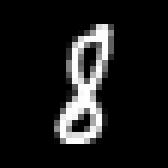

In [2]:
train_images, train_targets = load_mnist("train")
test_images, test_targets = load_mnist("test")
inputs, targets = next(iter(Stream(train_images, train_targets, batch_size=4, progress=False)))
test_inputs, test_targets = next(iter(Stream(test_images, test_targets, batch_size=4, progress=False)))
print("输入形状：", inputs.shape, "第一张的标签：", targets[0])
visualization.Image.from_tensor(inputs[0], value_range=(0, 1))

## 2. 从 patch 到类别

每个 patch 变为 8 维特征，位置表示加入顺序，Transformer 进行两次残差计算：
`x = x + Attention(LayerNorm(x))`，再 `x = x + FeedForward(LayerNorm(x))`。
最后平均所有位置，用 Linear 输出十类得分。

In [5]:
model = nn.Model([
    nn.PatchEmbedding(1, 8, patch_size=7),
    nn.PositionEmbedding(16, 8),
    nn.TransformerBlock(8, heads=2, hidden_features=16),
    nn.LayerNorm(8),
    nn.Mean(axis=1),
    nn.Linear(8, 10, seed=45),
])
optimizer = nn.SGD(model, learning_rate=0.01)
loss_function = nn.CrossEntropy()
# visualization.Network(model)

## 3. 训练两步

训练循环与 Iris 相同；这里改变的是模型与输入形状。

In [6]:
for step in range(2):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()
    print(f"step {step+1}  loss {loss.item():.6f}")

step 1  loss 2.175263
step 2  loss 2.361815


## 4. 测试与注意力

两步训练后的类别只用于检查流程。下方热图展示第一张图片、第一注意力头的 patch 关系。

In [8]:
scores = model(test_inputs, train=False)
predictions = scores.argmax(axis=-1)
visualization.Table(list(zip(test_targets, predictions)), columns=["真实数字", "预测数字"])

真实数字,预测数字
0,9
2,9
8,0
9,5


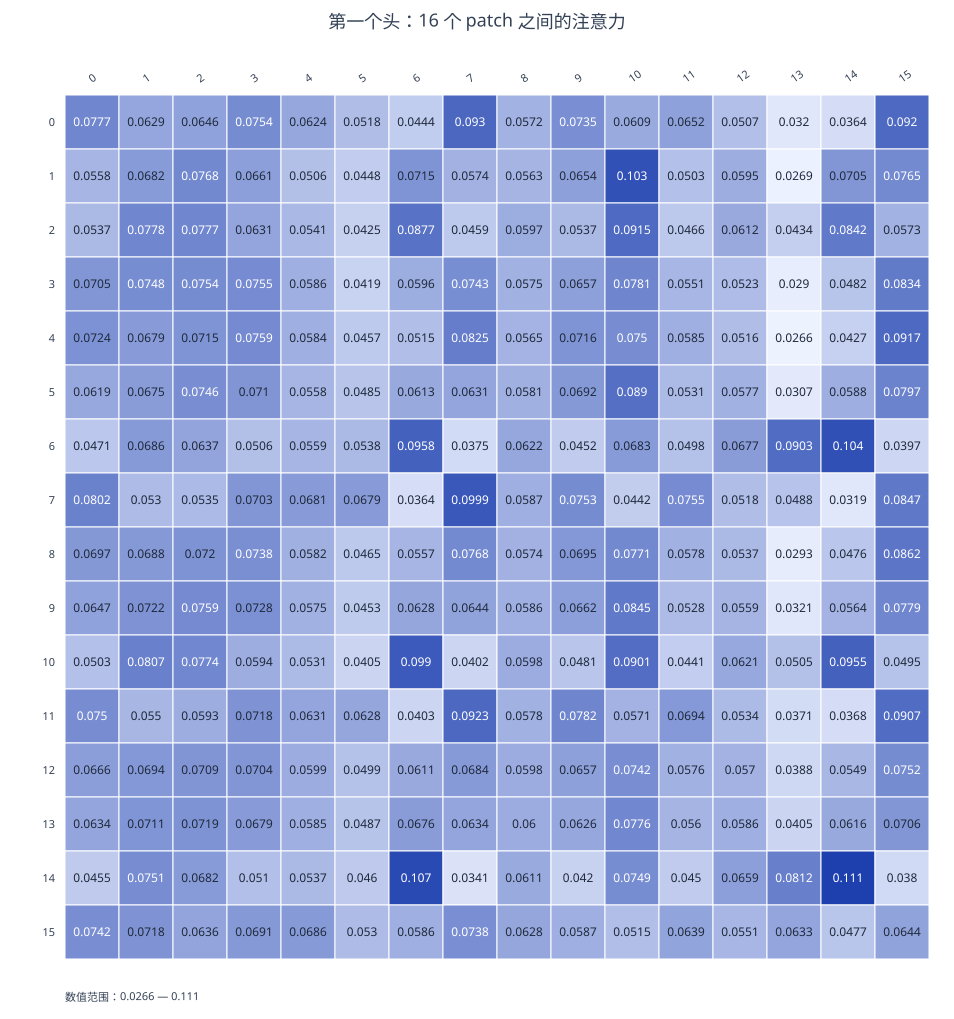

In [9]:
tokens = nn.Model(model.layers[:2])(inputs[:1], train=False)
block = model.layers[2]
weights = block.attention.weights(block.attention_norm(tokens))[0, 0]
visualization.Heatmap(weights.tolist(), title="第一个头：16 个 patch 之间的注意力")